@author: lajello
Tutorial on matplotlib fundamentals.
Matplotlibe documentation: https://matplotlib.org/stable/api/index.html

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.patches as patches

In [2]:
def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return h #m, m-h, m+h

## Data loading

**Titanic dataset**: https://www.kaggle.com/c/titanic#

**Dataset format:**

| Variable | Description | Values / Notes |
|---|---|---|
| `survival` | Survival | 0 = No, 1 = Yes |
| `pclass` | Ticket class | 1st, 2nd, 3rd |
| `sex` | Sex | male / female |
| `Age` | Age | In number of years |
| `sibsp` | Number of siblings + spouse aboard |  |
| `parch` | Number of parents + children aboard |  |
| `ticket` | Ticket number | |
| `fare` | Passenger fare | |
| `cabin` | Cabin number | |
| `embarked` | Port of embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |

<br>

**Tesco dataset** : https://figshare.com/articles/dataset/Area-level_grocery_purchases/7796666?file=18848363

See format description on Figshare

<br>

**FIFA 2019 dataset**: https://www.kaggle.com/roshansharma/fifa-data-visualization/data

See format description on Kaggle

<br>

**Gini coefficient nations**: https://data.oecd.org/inequality/income-inequality.htm

In [3]:
df_titanic = pd.read_csv('data/titanic/titanic.csv')
df_titanic.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


In [4]:
# some basic statistics and transformations for later plotting
df_titanic['Age_decade'] = df_titanic['Age']//10*10
df = df_titanic[['Age_decade','Fare','Survived']]
df = df.groupby('Age_decade').agg(['mean','std','count',mean_confidence_interval]).reset_index()
df = df[df['Age_decade'] < 80]
df

/var/folders/jf/0nvl5lz97m9gb6py4xb28b1c0000gn/T/ipykernel_66792/3505618848.py:4: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  m, se = np.mean(a), scipy.stats.sem(a)


Age_decade       Fare                                            Survived  \
                   mean        std count mean_confidence_interval      mean   
0        0.0  29.310059  25.619503    82                 5.629222  0.573171   
1       10.0  31.713172  48.256028   143                 7.977167  0.419580   
2       20.0  26.739255  43.292069   344                 4.591053  0.348837   
3       30.0  41.286781  69.885573   232                 9.040094  0.426724   
4       40.0  42.396421  50.053542   135                 8.520321  0.355556   
5       50.0  62.642201  76.843979    70                18.322800  0.414286   
6       60.0  71.716265  82.191105    31                      NaN  0.375000   
7       70.0  37.147629  30.224275     7                27.952792  0.142857   

                                            
        std count mean_confidence_interval  
0  0.497661    82                 0.109348  
1  0.495225   143                 0.081865  
2  0.477297   344                 0.050617  
3  0.495671   232                 0.064118  
4  0.480464   135                 0.081787  
5  0.496155    70                 0.118304  
6  0.491869    32                 0.177338  
7  0.377964     7                 0.349559

In [5]:
df_tesco = pd.read_csv('data/tesco/tesco.csv')

In [6]:
list(df_tesco.columns)

['msoa',
 'imd',
 'income',
 'employment',
 'education',
 'health',
 'crime',
 'barriers',
 'living_environment',
 'hypertension',
 'obesity',
 'diabetes',
 'cholesterol',
 'area_id',
 'weight',
 'weight_perc2.5',
 'weight_perc25',
 'weight_perc50',
 'weight_perc75',
 'weight_perc97.5',
 'weight_std',
 'weight_ci95',
 'volume',
 'volume_perc2.5',
 'volume_perc25',
 'volume_perc50',
 'volume_perc75',
 'volume_perc97.5',
 'volume_std',
 'volume_ci95',
 'fat',
 'fat_perc2.5',
 'fat_perc25',
 'fat_perc50',
 'fat_perc75',
 'fat_perc97.5',
 'fat_std',
 'fat_ci95',
 'saturate',
 'saturate_perc2.5',
 'saturate_perc25',
 'saturate_perc50',
 'saturate_perc75',
 'saturate_perc97.5',
 'saturate_std',
 'saturate_ci95',
 'salt',
 'salt_perc2.5',
 'salt_perc25',
 'salt_perc50',
 'salt_perc75',
 'salt_perc97.5',
 'salt_std',
 'salt_ci95',
 'sugar',
 'sugar_perc2.5',
 'sugar_perc25',
 'sugar_perc50',
 'sugar_perc75',
 'sugar_perc97.5',
 'sugar_std',
 'sugar_ci95',
 'protein',
 'protein_perc2.5',
 'prot

In [7]:
df_gini = pd.read_csv('data/gini.csv')
df_gini = df_gini[(df_gini['TIME'] == 2018) & (df_gini['SUBJECT'] == 'GINI')][['LOCATION','Value']]
print(len(df_gini))
df_gini.head()

31


,LOCATION,Value
15,AUS,0.325
63,AUT,0.280
67,BEL,0.258
242,CAN,0.303
303,CZE,0.249


In [8]:
df_gas = pd.read_csv('data/gas_prices.csv', dtype={'Year':int})
df_gas 

,Year,Australia,Canada,France,Germany,Italy,Japan,Mexico,South Korea,UK,USA
0,1990,NaN,1.87,3.63,2.65,4.59,3.16,1.00,2.05,2.82,1.16
1,1991,1.96,1.92,3.45,2.90,4.50,3.46,1.30,2.49,3.01,1.14
2,1992,1.89,1.73,3.56,3.27,4.53,3.58,1.50,2.65,3.06,1.13
3,1993,1.73,1.57,3.41,3.07,3.68,4.16,1.56,2.88,2.84,1.11
4,1994,1.84,1.45,3.59,3.52,3.70,4.36,1.48,2.87,2.99,1.11
5,1995,1.95,1.53,4.26,3.96,4.00,4.43,1.11,2.94,3.21,1.15
6,1996,2.12,1.61,4.41,3.94,4.39,3.64,1.25,3.18,3.34,1.23
7,1997,2.05,1.62,4.00,3.53,4.07,3.26,1.47,3.34,3.83,1.23
8,1998,1.63,1.38,3.87,3.34,3.84,2.82,1.49,3.04,4.06,1.06
9,1999,1.72,1.52,3.85,3.42,3.87,3.27,1.79,3.80,4.29,1.17


In [9]:
df_fifa = pd.read_csv('data/fifa_data.csv')
df_fifa.columns

Index(['Unnamed: 0', 'ID', 'Name', 'Age', 'Photo', 'Nationality', 'Flag',
       'Overall', 'Potential', 'Club', 'Club Logo', 'Value', 'Wage', 'Special',
       'Preferred Foot', 'International Reputation', 'Weak Foot',
       'Skill Moves', 'Work Rate', 'Body Type', 'Real Face', 'Position',
       'Jersey Number', 'Joined', 'Loaned From', 'Contract Valid Until',
       'Height', 'Weight', 'LS', 'ST', 'RS', 'LW', 'LF', 'CF', 'RF', 'RW',
       'LAM', 'CAM', 'RAM', 'LM', 'LCM', 'CM', 'RCM', 'RM', 'LWB', 'LDM',
       'CDM', 'RDM', 'RWB', 'LB', 'LCB', 'CB', 'RCB', 'RB', 'Crossing',
       'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling',
       'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration',
       'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower',
       'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression',
       'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure',
       'Marking', 'StandingTackle', 'SlidingT

## Plotting basics - Examples

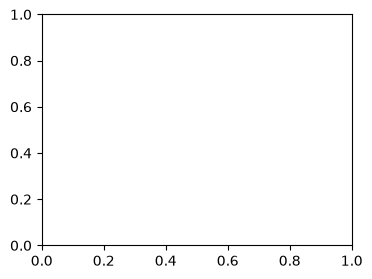

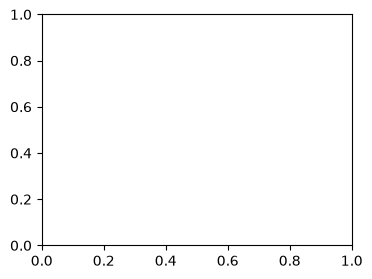

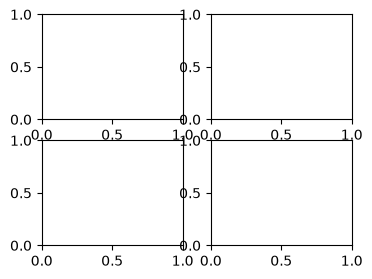

In [10]:
# create a figure with 4:3 aspect ratio (4 inches wide, 3 inches tall)
# create a figure 4 x 3 inches
fig = plt.figure(figsize=(4,3)) 
# add a subplot to the figure ...
ax = fig.add_subplot() 

# ... or alternative short form
fig, ax = plt.subplots(figsize=(4,3))

# grid of i x j plots
fig, axs = plt.subplots(2, 2, figsize=(4,3))

# select the top left plot
ax = axs[0][0]

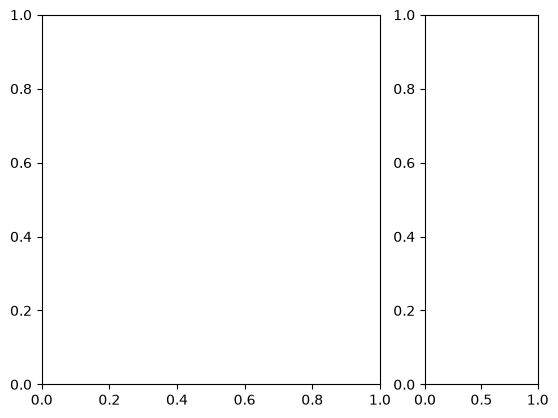

In [11]:
# plot it
fix, (ax1, ax2) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [3, 1]})
fig.tight_layout()
plt.savefig('fundamentals.png', transparent=False, dpi=400)

## Example plots - Titanic Dataset

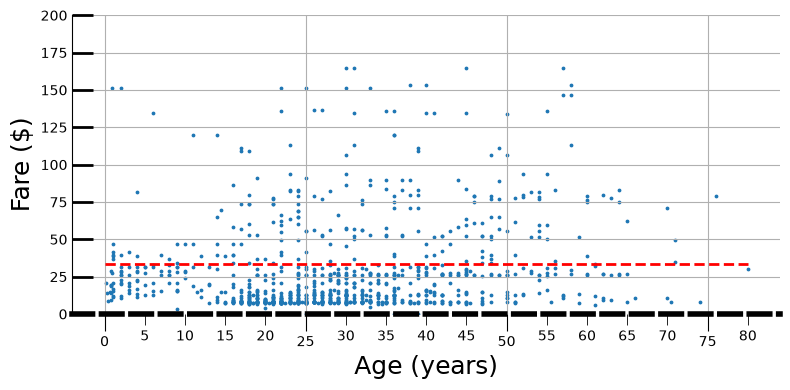

In [12]:
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(df_titanic.Age,df_titanic.Fare, s=3)

avg_fare = df_titanic.Fare.mean()

ax.set_ylim(0,200)
ax.set_ylabel('Fare ($)', fontsize=18)
ax.set_xlabel('Age (years)', fontsize=18)

# configuring the ticks
ax.tick_params(axis='y', direction='in', length=15, width=2)
ax.tick_params(axis='x', length=12)
ax.tick_params(axis='x', which='minor', length=8)

# using locators to configure the x axis
ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_major_formatter('{x:.0f}')
# For the minor ticks, use no labels; default NullFormatter.
ax.xaxis.set_minor_locator(MultipleLocator(5))
ax.xaxis.set_minor_formatter('{x:.0f}')

# configure the spine around the plot
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.spines['bottom'].set_linewidth(4)
ax.spines['bottom'].set_linestyle('dashed')

# adding lines directly to the plot
ax.hlines(avg_fare, 0, 80, linestyle='--', color='red', linewidth=2)
ax.grid()

plt.tight_layout()
plt.savefig('fundamentals-1.png', transparent=False, dpi=400)

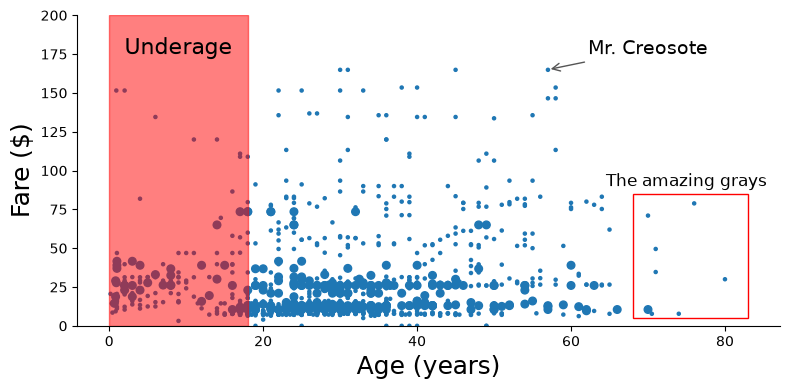

In [13]:
fig, ax = plt.subplots(figsize=(8,4))
sizes = df_titanic.Pclass
sizes = [5  if _ != 2 else 30 for _ in sizes]
ax.scatter(df_titanic.Age,df_titanic.Fare, s=sizes)

avg_fare = df_titanic.Fare.mean()

ax.set_ylim(0,200)
ax.set_ylabel('Fare ($)', fontsize=18)
ax.set_xlabel('Age (years)', fontsize=18)

# configure the spine
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# add custom text directly to the plot
ax.annotate('Mr. Creosote', (57,165), (70,175), 
            ha='center', arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=14)
ax.text(9, 175, 'Underage', ha='center', fontsize=16)

# add a span to the plot to highlight an area
plt.axvspan(0, 18, color='red', alpha=0.5)

# create a Rectangle patch
rect = patches.Rectangle((68, 5), 15, 80, linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(rect)
ax.text(75, 90, 'The amazing grays', ha='center', fontsize=12)

plt.tight_layout()
plt.savefig('fundamentals-2.png', transparent=False, dpi=400)

## Plotting data from Foursquare

In [14]:
# read data, parsing the column "date" as a date
df = pd.read_csv('data/foursquare/foursquare_groupedNewYork.csv', 
                 parse_dates=['date'], 
                 usecols=['date', 'categoryname', 'demo', 'visits'])
# make sure that records are sorted by date
df = df.sort_values(by='date')
# select the data about the visits to grocery stores
df = df[(df['categoryname']=='Grocery') & (df['demo']=='All')]
df = df[['date','visits']]

/var/folders/jf/0nvl5lz97m9gb6py4xb28b1c0000gn/T/ipykernel_66792/1066551960.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([0,'1M','2M','3M','4M'])


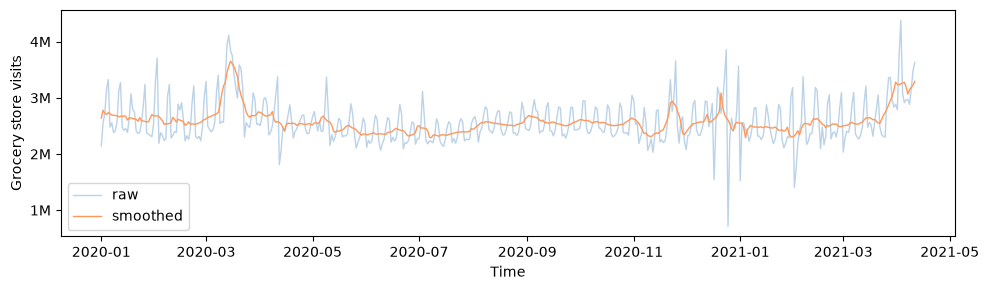

In [15]:
# apply smoothing on a 7-day rolling window
df_smooth = df.rolling(window=7, min_periods=1, on='date', center=True).mean()

# plotting the original and smoothed curves
fig,ax = plt.subplots(1,1,figsize=(10,3))
plt.plot(df['date'],df['visits'],'-',linewidth=1,alpha=0.7,label='raw',color='#9FC0DE')
plt.plot(df_smooth['date'],df_smooth['visits'],'-',linewidth=1,label='smoothed',color='#FF985A')
ax.set_yticklabels([0,'1M','2M','3M','4M'])
ax.set_ylabel('Grocery store visits')
ax.set_xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig('foursquare_groceries.png', dpi=400)

## Plotting Tesco Data

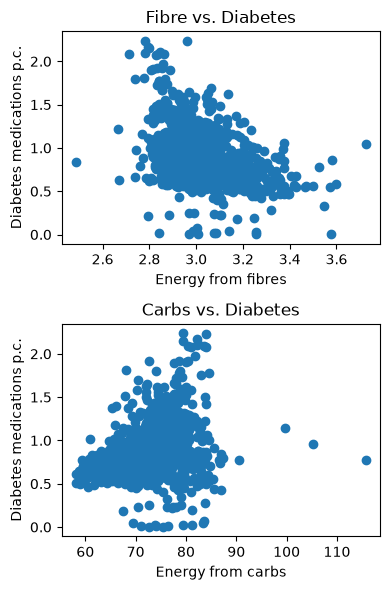

In [16]:
# a first basic scatterplot 
fig, axs = plt.subplots(2, 1, figsize=(4,6))
ax1, ax2 = axs

ax1.scatter(df_tesco['energy_fibre'], df_tesco['diabetes'])
ax1.set_xlabel('Energy from fibres')
ax1.set_ylabel('Diabetes medications p.c.')
ax1.set_title('Fibre vs. Diabetes')

ax2.scatter(df_tesco['energy_carb'], df_tesco['diabetes'])
ax2.set_ylabel('Diabetes medications p.c.')
ax2.set_xlabel('Energy from carbs')
ax2.set_title('Carbs vs. Diabetes')

plt.tight_layout()
plt.savefig('medication-first.png', transparent=False, dpi=400)

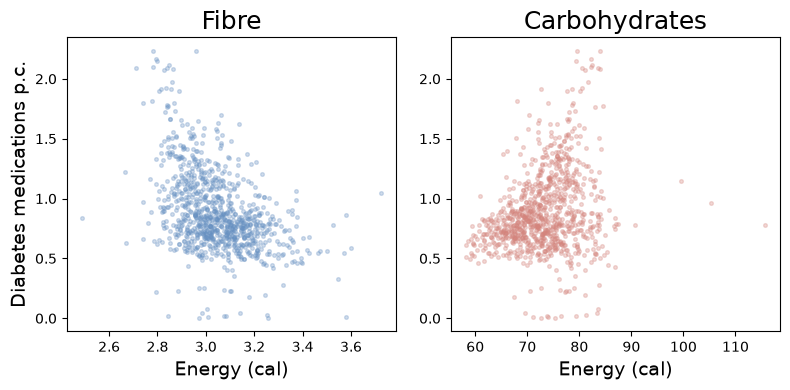

In [17]:
# improving visual appearance

# a first basic scatterplot 
fig, axs = plt.subplots(1, 2, figsize=(8,4))
ax1, ax2 = axs

ax1.scatter(df_tesco['energy_fibre'], df_tesco['diabetes'], s=7, c='#6791c2', alpha=0.3)
ax1.set_xlabel('Energy (cal)', fontsize=14)
ax1.set_ylabel('Diabetes medications p.c.', fontsize=14)
ax1.set_title('Fibre', fontsize=18)

ax2.scatter(df_tesco['energy_carb'], df_tesco['diabetes'], s=7, c='#d4847c', alpha=0.3)
ax2.set_xlabel('Energy (cal)', fontsize=14)
ax2.set_title('Carbohydrates', fontsize=18)

plt.tight_layout()
plt.savefig('medications-improved.png', transparent=False, dpi=400)

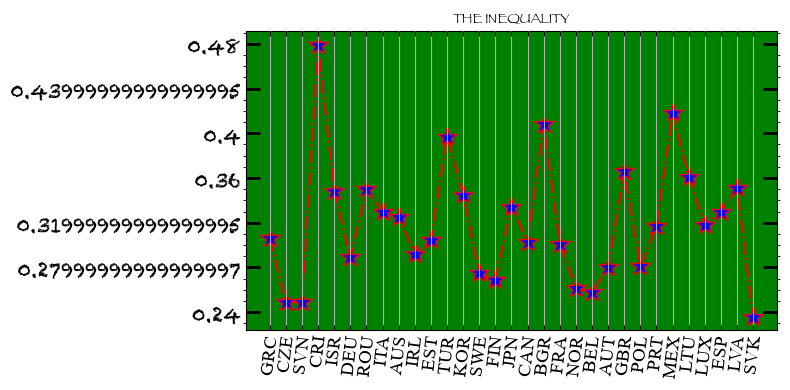

In [18]:
#ugly example
fig, ax = plt.subplots(figsize=(8,4))
df_gini = df_gini.sample(frac=1)
x = df_gini['LOCATION']
y = df_gini['Value']

ax.plot(x,y,'-.*', markersize=15, color='red', markerfacecolor='blue')

ax.tick_params(axis='y', direction='in', length=10, width=2)
plt.xticks(fontsize=3, fontname = 'Times New Roman') 
plt.yticks(fontsize=3, fontname = 'Chalkduster') 
plt.xticks(rotation=83)

ax.set_facecolor('green')
ax.yaxis.set_major_locator(MultipleLocator(0.04))
ax.yaxis.set_major_formatter('{x}')
# For the minor ticks, use no labels; default NullFormatter.
ax.yaxis.set_minor_locator(MultipleLocator(0.01))

ax.tick_params(labelsize=14, direction='in')

ax.yaxis.set_ticks_position('both')
ax.xaxis.set_ticks_position('both')

ax.set_axisbelow(False)
ax.set_title('THE INEQUALITY', font='Papyrus')
ax.grid(axis='x')

plt.tight_layout()
plt.savefig('ugly-example.png', transparent=False, dpi=80)

### Logarithmic scales

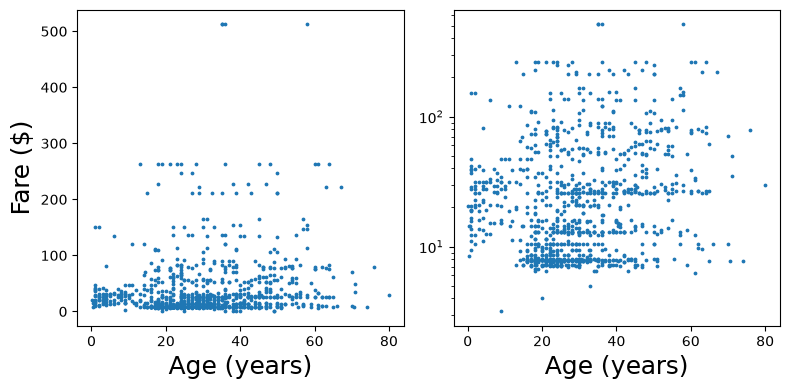

In [19]:
fig, axs = plt.subplots(1,2,figsize=(8,4))
ax1, ax2 = axs
ax1.scatter(df_titanic.Age,df_titanic.Fare, s=3)
ax2.scatter(df_titanic.Age,df_titanic.Fare, s=3)
# plot the y-axis in logarithmic scale to "unflatten" the picture
ax2.set_yscale('log')

ax1.set_ylabel('Fare ($)', fontsize=18)
ax1.set_xlabel('Age (years)', fontsize=18)
ax2.set_xlabel('Age (years)', fontsize=18)
plt.tight_layout()
plt.savefig('logarithmic-plot.png', transparent=False, dpi=400)